Practical: Hierarchical Clustering on the Iris Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Display first five rows
print(df.head())

# Display dataset information
print("\nDataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)

Column Names:
Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'],
      dtype='object')

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [3]:
# Select input features
X = df

# Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Data:")
print(X_scaled[:5])

Scaled Data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


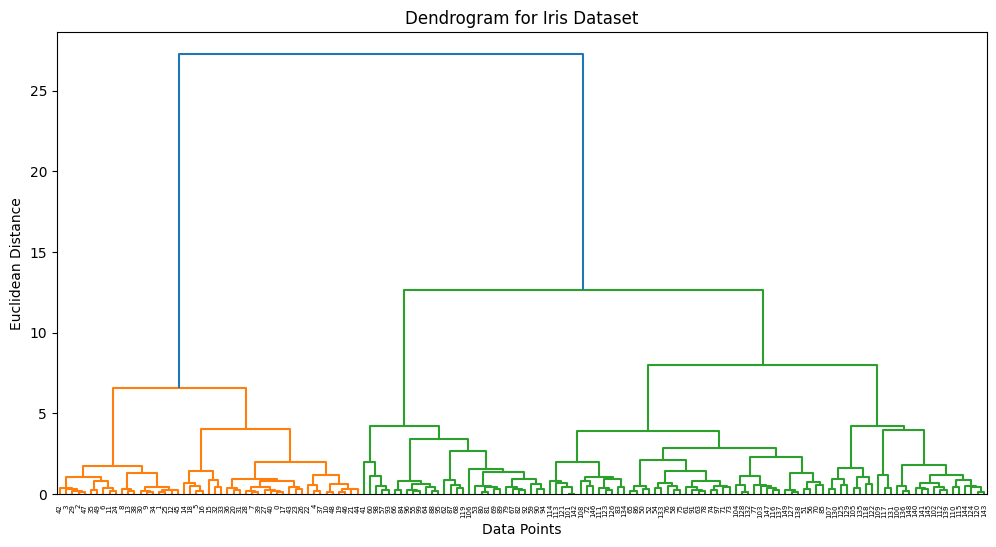

In [4]:
# Create linkage matrix
linked = linkage(X_scaled, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Dendrogram for Iris Dataset")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

In [5]:
# Apply Hierarchical Clustering
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

hc_labels = hc.fit_predict(X_scaled)

# Add cluster labels to dataset
df['Hierarchical_Cluster'] = hc_labels

print("Hierarchical Cluster Labels:")
print(hc_labels)

print("\nNumber of points in each cluster:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

Hierarchical Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]

Number of points in each cluster:
Hierarchical_Cluster
0    71
1    49
2    30
Name: count, dtype: int64


In [6]:
# Calculate Silhouette Score
hc_score = silhouette_score(X_scaled, hc_labels)

print("Hierarchical Clustering Silhouette Score:",
      round(hc_score, 4))

Hierarchical Clustering Silhouette Score: 0.4467


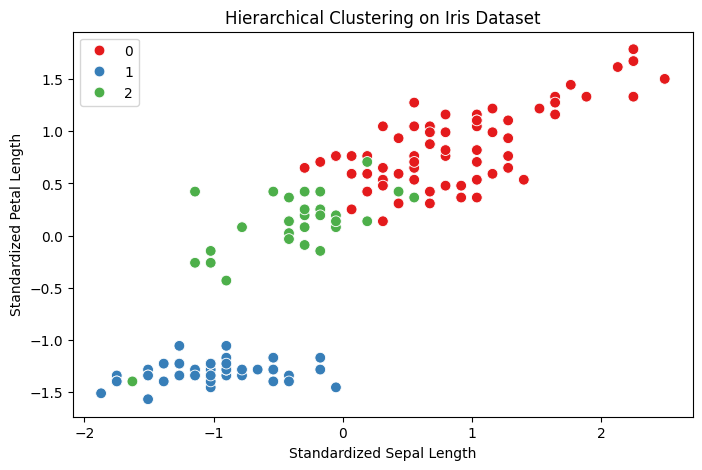

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 2],
    hue=hc_labels,
    palette='Set1',
    s=60
)

plt.title("Hierarchical Clustering on Iris Dataset")
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Petal Length")
plt.show()

In [8]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train model and predict clusters
km_labels = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Labels:")
print(km_labels)

# Calculate Silhouette Score
km_score = silhouette_score(X_scaled, km_labels)

print("\nK-Means Silhouette Score:",
      round(km_score, 4))

K-Means Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]

K-Means Silhouette Score: 0.4599


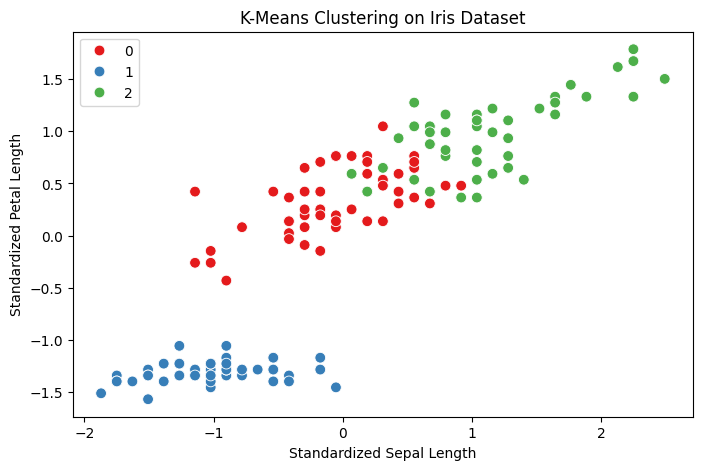

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 2],
    hue=km_labels,
    palette='Set1',
    s=60
)

plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Standardized Sepal Length")
plt.ylabel("Standardized Petal Length")
plt.show()

                 Algorithm  Silhouette Score
0  Hierarchical Clustering          0.446689
1       K-Means Clustering          0.459948


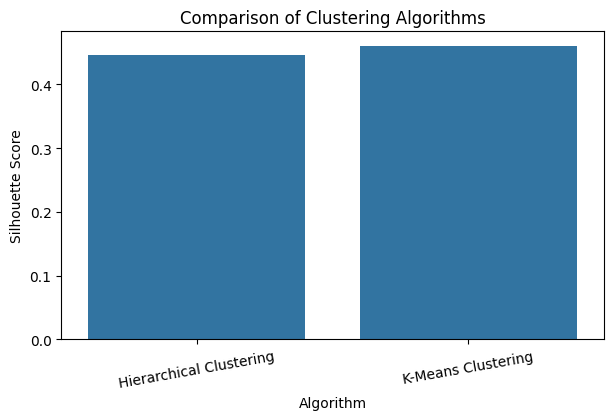

In [10]:
# Compare cluster quality
comparison = pd.DataFrame({
    'Algorithm': ['Hierarchical Clustering', 'K-Means Clustering'],
    'Silhouette Score': [hc_score, km_score]
})

print(comparison)

# Plot comparison
plt.figure(figsize=(7, 4))

sns.barplot(
    data=comparison,
    x='Algorithm',
    y='Silhouette Score'
)

plt.title("Comparison of Clustering Algorithms")
plt.ylabel("Silhouette Score")
plt.xticks(rotation=10)
plt.show()

In [11]:
# Actual species labels (used only for evaluation)
actual_labels = iris.target

hc_ari = adjusted_rand_score(actual_labels, hc_labels)
km_ari = adjusted_rand_score(actual_labels, km_labels)

print("Hierarchical Clustering ARI:", round(hc_ari, 4))
print("K-Means Clustering ARI:", round(km_ari, 4))

Hierarchical Clustering ARI: 0.6153
K-Means Clustering ARI: 0.6201


In [ ]:
from sklearn.decomposition import PCA

# Reduce data to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Hierarchical Clustering
axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=hc_labels, cmap='Set1'
)
axes[0].set_title("Hierarchical Clustering")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")

# K-Means Clustering
axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=km_labels, cmap='Set1'
)
axes[1].set_title("K-Means Clustering")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")

plt.tight_layout()
plt.show()